# 티라노사우루스 발성 범위 추정 — 음원-필터 모델 + 몬테카를로 + Sobol 민감도

보고서 「음원-필터 모델로 본 티라노사우루스(Tyrannosaurus rex)의 발성 범위 추정」의 계산 코드입니다.
Google Colab에서 **런타임 → 모두 실행**으로 그대로 돌아갑니다.

| 칸 | 내용 | 보고서 |
|---|---|---|
| [0] | 준비, 버전 출력 | Ⅱ-5 재현성 |
| [1] | 매개변수 | 표 1 |
| [2] | Openwind 관 공명 수치 실험 → 통로 공식 오차 κ | Ⅲ장, 표 2 |
| [3] | 모델 (음원·필터) | Ⅱ-1 |
| [4] | 몬테카를로 + 거름 | Ⅳ장 |
| [5] | 그림 1 | 그림 1 |
| [6] | 수렴 확인 | Ⅱ-5 수렴 확인 |
| [7] | Sobol 민감도 | Ⅴ장 |
| [8] | 그림 2 | 그림 2 |

In [1]:
# %% [0] 준비 — Colab 첫 실행 시 SALib·Openwind·한글 글꼴 설치, 버전 출력
import sys, subprocess, os, glob, warnings
if "google.colab" in sys.modules:
    subprocess.run("pip -q install SALib openwind", shell=True)
    subprocess.run("apt-get -qq install -y fonts-nanum > /dev/null", shell=True)
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib import font_manager as fm
from SALib.sample import sobol as sobol_sample
from SALib.analyze import sobol as sobol_analyze

for f in ["/usr/share/fonts/truetype/nanum/NanumGothic.ttf"] + glob.glob("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"):
    if os.path.exists(f):
        fm.fontManager.addfont(f); plt.rcParams["font.family"] = fm.FontProperties(fname=f).get_name(); break
if plt.rcParams["font.family"] == ["sans-serif"]:
    for name in ["Noto Sans CJK KR", "Malgun Gothic", "AppleGothic"]:
        if any(name in x.name for x in fm.fontManager.ttflist):
            plt.rcParams["font.family"] = name; break
plt.rcParams["axes.unicode_minus"] = False

import importlib.metadata as md
def _ver(p):
    try: return md.version(p)
    except md.PackageNotFoundError: return "없음"
print("실행 환경: Python", sys.version.split()[0], "|",
      " | ".join(f"{p} {_ver(p)}" for p in ["numpy", "scipy", "pandas", "SALib", "openwind"]))

SEED_MC, SEED_SOBOL = 2026, 1           # 난수 시드 (보고서 Ⅱ-5)
rng = np.random.default_rng(SEED_MC)

실행 환경: Python 3.13.18 | numpy 2.5.3 | scipy 1.18.1 | pandas 3.0.5 | SALib 1.6.0 | openwind 0.12.4


In [2]:
# %% [1] 매개변수 — 범위와 근거 (보고서 표 1과 같은 값)
P = dict(
    M=(6000, 9500),          # 몸무게 kg, 균등분포 (Hutchinson 외 2011)
    kL=(0.75, 1.25),         # 막 길이 회귀식 L0=3.28*M^0.4 mm 의 외삽 보정 배수 (가정)
    a_mean=2.4, a_sd=2.9,    # 응력 상수 a kPa, 로그정규 (Riede 외 2015 표 1)
    b_mean=16.2, b_sd=3.1,   # 응력 지수 b, 정규 (Riede 외 2015 표 1)
    eps_min=0.03,            # 최소 늘임 (Riede 외 2015 시험 범위 하한)
    eps_max=(0.15, 0.35),    # 최대 늘임, 균등 (상한 0.35 = 시험 범위 상한, 하한은 가정)
    rho=1040.0,              # 조직 밀도 kg/m^3 (Titze 외 2016)
    c=(351, 356),            # 음속 m/s, 체온 36.3±2.5℃ (Flores 외 2026) + 습도 보정
    Lup=(1.2, 1.5),          # 후두→입 통로 m (Brochu 2003; Carr 2020)
    r=(0.03, 0.08),          # 통로 반지름 m (가정) — 열린 끝 보정에 쓰임
    Lneck=(1.0, 1.4),        # 목 구간 기관 m (목뼈 치수로 추정, 가정 포함)
    Lchest=(0.1, 0.5),       # 가슴 안 기관 m (가정)
    phi=(0.001, 0.01),       # 닫힌 소리: 주머니 부피 / 몸 부피 (가정)
    rn=(0.02, 0.06),         # 닫힌 소리: 주머니 입구 반지름 m (가정)
    ln=(0.05, 0.20),         # 닫힌 소리: 주머니 입구 길이 m (가정)
    hear=(10, 3000),         # 거름: 청각 범위 Hz (상한 Gleich 외 2005)
    allo_factor=4.0,         # 거름: 몸무게 예측 최저 F0의 몇 배 범위까지 허용 (Riede 외 2019 그림 6)
    N=50_000,                # 조합마다 계산 횟수
    N_sobol=4096,            # Sobol 기준 표본 수 (총 계산 = N_sobol × (2D+2))
)

In [3]:
# %% [2] Openwind 관 공명 수치 실험 — 통로 공식 검증 (보고서 Ⅲ장, 표 2)
# 후두형·울대형 통로 길이의 최소·중간·최대(1.2–3.4 m) × 반지름 3, 5.5, 8 cm = 18개 관을 체온 36.3℃에서 계산하고
# 첫째 공명을 단순 공식 c/4L, 끝 보정 공식 c/4(L+0.61r)과 비교한다.
# Openwind/끝보정 비율의 평균·표준편차가 시뮬레이션의 오차 항 κ가 된다.
T_BODY = 36.3
c_body = 331.3 + 0.606 * T_BODY
LENGTHS = [P["Lup"][0], np.mean(P["Lup"]), P["Lup"][1],                                   # 후두형 1.2, 1.35, 1.5
           P["Lup"][0] + P["Lneck"][0] + P["Lchest"][0],                                   # 울대형 최소 2.3
           np.mean(P["Lup"]) + np.mean(P["Lneck"]) + np.mean(P["Lchest"]),                 # 울대형 중간 2.85
           P["Lup"][1] + P["Lneck"][1] + P["Lchest"][1]]                                   # 울대형 최대 3.4
RADII = [0.03, 0.055, 0.08]

def openwind_f1(L, r, T):
    """Openwind로 한쪽이 막힌 원통관의 입력 임피던스를 계산해 첫째 공명 주파수를 구한다."""
    from openwind import ImpedanceComputation
    c0 = 331.3 + 0.606 * T
    guess = c0 / (4 * L)
    f = np.arange(0.6 * guess, 1.4 * guess, 0.005)
    res = ImpedanceComputation(f, [[0, L, r, r, "linear"]], temperature=T)
    return f[np.argmax(np.abs(res.impedance))]

try:
    rows = []
    for L in LENGTHS:
        for r in RADII:
            fo = openwind_f1(L, r, T_BODY)
            fp = c_body / (4 * L); fc = c_body / (4 * (L + 0.61 * r))
            rows.append(dict(통로길이=round(L, 2), 반지름=r, 단순공식=fp, 끝보정공식=fc, Openwind=fo,
                             비율_단순=fo / fp, 비율_끝보정=fo / fc))
    OW = pd.DataFrame(rows)
    OW.round(4).to_csv("result_openwind.csv", index=False, encoding="utf-8-sig")
    print("[표 2] 반지름 5.5 cm 관의 첫째 공명 (Hz)\n",
          OW[OW.반지름 == 0.055].drop(columns="반지름").round(3).to_string(index=False))
    print(f"\n18개 관 — Openwind/단순 공식: {OW.비율_단순.mean():.3f} ± {OW.비율_단순.std():.3f} "
          f"(최대 차이 {(1 - OW.비율_단순.min()) * 100:.1f}%)")
    print(f"18개 관 — Openwind/끝 보정 공식: {OW.비율_끝보정.mean():.3f} ± {OW.비율_끝보정.std():.3f}")
    KAPPA = (OW.비율_끝보정.mean(), OW.비율_끝보정.std())
except ImportError:
    # Openwind 설치가 안 될 때: 보고서 Ⅲ장의 18개 관 결과를 그대로 사용
    print("Openwind를 불러오지 못해 보고서 Ⅲ장의 값(0.998 ± 0.003)을 사용합니다.")
    KAPPA = (0.998, 0.003)

[표 2] 반지름 5.5 cm 관의 첫째 공명 (Hz)
  통로길이   단순공식  끝보정공식  Openwind  비율_단순  비율_끝보정
 1.20 73.604 71.602    71.572  0.972   1.000
 1.35 65.426 63.839    63.800  0.975   0.999
 1.50 58.883 57.595    57.545  0.977   0.999
 2.30 38.402 37.850    37.781  0.984   0.998
 2.85 30.991 30.630    30.560  0.986   0.998
 3.40 25.978 25.724    25.652  0.987   0.997

18개 관 — Openwind/단순 공식: 0.980 ± 0.008 (최대 차이 3.8%)
18개 관 — Openwind/끝 보정 공식: 0.998 ± 0.003


In [4]:
# %% [3] 모델 — 음원(줄 모델) + 필터(관 공명 / 헬름홀츠 공명)  (보고서 Ⅱ-1)
def lognorm_params(m, s):
    sl = np.sqrt(np.log(1 + (s / m) ** 2)); return np.log(m) - sl**2 / 2, sl

def f0(L0_m, a_kpa, b, eps, rho):
    sigma = a_kpa * 1e3 * np.exp(b * eps)            # 응력 Pa:  σ = a·e^(bε)
    return 1 / (2 * L0_m * (1 + eps)) * np.sqrt(sigma / rho)

def tube_f1(c, L, r, kappa=1.0):   # 한쪽이 막힌 관 + 열린 끝 보정:  κ · c / 4(L + 0.61r)
    return kappa * c / (4 * (L + 0.61 * r))

def helmholtz(c, M, phi, rn, ln):  # 닫힌 소리: 주머니 공명
    V = phi * M / 1000.0; A = np.pi * rn**2; leff = ln + 1.7 * rn
    return c / (2 * np.pi) * np.sqrt(A / (V * leff))

def draw(n, rng):
    u = lambda k: rng.uniform(*P[k], n)
    mu, sl = lognorm_params(P["a_mean"], P["a_sd"])
    return dict(M=u("M"), kL=u("kL"), a=rng.lognormal(mu, sl, n),
                b=np.clip(rng.normal(P["b_mean"], P["b_sd"], n), 1, None),
                eps_max=u("eps_max"), c=u("c"), Lup=u("Lup"), r=u("r"), Lneck=u("Lneck"),
                Lchest=u("Lchest"), phi=u("phi"), rn=u("rn"), ln=u("ln"),
                kappa=rng.normal(KAPPA[0], KAPPA[1], n) if KAPPA[1] > 0 else np.full(n, KAPPA[0]))

CASES = ["후두+열린", "후두+닫힌", "울대+열린", "울대+닫힌"]

def run_case(case, x):
    L0 = 3.28e-3 * x["M"] ** 0.4 * x["kL"]     # m
    lo = f0(L0, x["a"], x["b"], P["eps_min"], P["rho"])
    hi = f0(L0, x["a"], x["b"], x["eps_max"], P["rho"])
    Lt = x["Lup"] if case.startswith("후두") else x["Lup"] + x["Lneck"] + x["Lchest"]
    if case.endswith("열린"):
        res = tube_f1(x["c"], Lt, x["r"], x["kappa"])
    else:
        res = helmholtz(x["c"], x["M"], x["phi"], x["rn"], x["ln"])
    return lo, hi, res, Lt

In [5]:
# %% [4] 몬테카를로 + 거름  (보고서 Ⅳ장)
def simulate(N, rng):
    summary, store = [], {}
    for case in CASES:
        x = draw(N, rng)
        lo, hi, res, Lt = run_case(case, x)
        allo = 450 * x["M"] ** -0.38
        keep = (hi >= P["hear"][0]) & (lo <= P["hear"][1]) & (res <= P["hear"][1]) \
               & (lo <= allo * P["allo_factor"]) & (lo >= allo / P["allo_factor"])
        inter = (res >= lo * 0.8) & (res <= hi * 1.2)      # F0 범위와 공명이 겹침 → 음원-통로 상호작용 주의
        store[case] = dict(lo=lo[keep], hi=hi[keep], res=res[keep])
        q = lambda v: np.percentile(v[keep], [5, 50, 95])
        summary.append(dict(조합=case, 통과율=keep.mean(),
                            최저F0_5=q(lo)[0], 최저F0_50=q(lo)[1], 최저F0_95=q(lo)[2],
                            최고F0_5=q(hi)[0], 최고F0_50=q(hi)[1], 최고F0_95=q(hi)[2],
                            공명_5=q(res)[0], 공명_50=q(res)[1], 공명_95=q(res)[2],
                            상호작용비율=inter[keep].mean()))
    return pd.DataFrame(summary), store

S, store = simulate(P["N"], rng)
pd.set_option("display.width", 200)
print("[네 조합의 범위] (Hz, 5–50–95 백분위)\n", S.round(2).to_string(index=False))
S.round(3).to_csv("result_ranges.csv", index=False, encoding="utf-8-sig")

[네 조합의 범위] (Hz, 5–50–95 백분위)
    조합  통과율  최저F0_5  최저F0_50  최저F0_95  최고F0_5  최고F0_50  최고F0_95  공명_5  공명_50  공명_95  상호작용비율
후두+열린 0.85    4.14     7.10    15.29   13.47    34.79   125.41 58.04  63.73  70.66    0.29
후두+닫힌 0.84    4.14     7.09    15.35   13.45    35.17   125.92 23.62  45.46  94.32    0.47
울대+열린 0.85    4.13     7.10    15.40   13.32    34.94   122.78 27.64  30.57  34.26    0.67
울대+닫힌 0.85    4.14     7.09    15.19   13.42    35.08   124.69 23.67  45.73  95.31    0.46


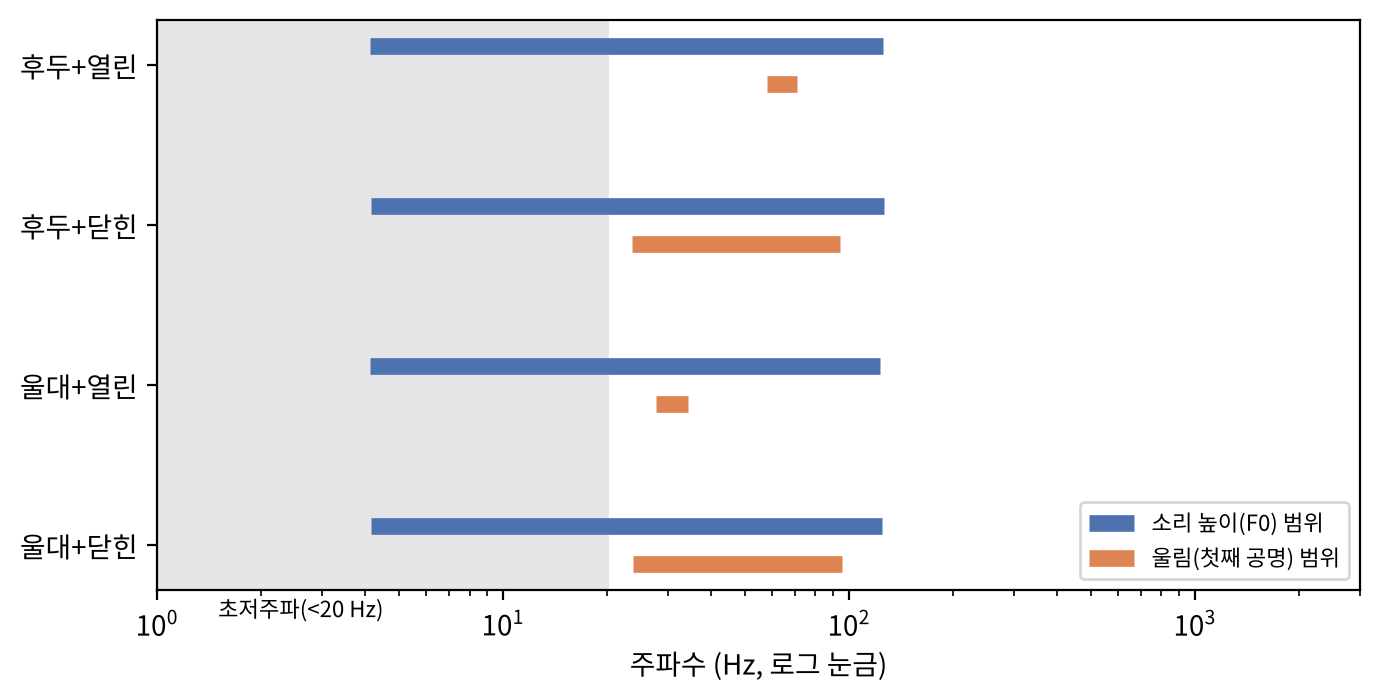

In [6]:
# %% [5] 그림 1 — 네 조합의 범위 도표
fig, ax = plt.subplots(figsize=(7, 3.6))
for i, r in S.iterrows():
    y = len(S) - i
    ax.plot([r.최저F0_5, r.최고F0_95], [y + 0.12] * 2, lw=6, color="#4C72B0", solid_capstyle="butt",
            label="소리 높이(F0) 범위" if i == 0 else None)
    ax.plot([r.공명_5, r.공명_95], [y - 0.12] * 2, lw=6, color="#DD8452", solid_capstyle="butt",
            label="울림(첫째 공명) 범위" if i == 0 else None)
ax.set_yticks(range(len(S), 0, -1), S.조합)
ax.set_xscale("log"); ax.set_xlabel("주파수 (Hz, 로그 눈금)")
ax.axvspan(1, 20, color="0.9", zorder=0); ax.text(1.5, 0.55, "초저주파(<20 Hz)", fontsize=8)
ax.legend(fontsize=8, loc="lower right"); ax.set_xlim(1, 3000)
plt.tight_layout(); plt.savefig("fig1_ranges.png", dpi=200); plt.show()

In [7]:
# %% [6] 수렴 확인 — 표본 수를 절반으로 줄여도 범위가 그대로인가  (보고서 Ⅱ-5)
S_half, _ = simulate(P["N"] // 2, np.random.default_rng(SEED_MC))
cols = [c for c in S.columns if c.startswith(("최저", "최고", "공명"))]
change = ((S_half[cols] - S[cols]).abs() / S[cols] * 100).values.max()
print(f"표본 {P['N']:,}회 → {P['N'] // 2:,}회: 5–50–95 백분위 값의 최대 변화 {change:.1f}%")

표본 50,000회 → 25,000회: 5–50–95 백분위 값의 최대 변화 2.0%


In [8]:
# %% [7] 민감도 분석 (Sobol) — 어떤 미지수가 폭을 흔드는가  (보고서 Ⅴ장)
mu, sl = lognorm_params(P["a_mean"], P["a_sd"])
def problem(names, bounds, dists):
    return dict(num_vars=len(names), names=names, bounds=bounds, dists=dists)
NS = P["N_sobol"]

prob_src = problem(["몸무게", "막길이 보정", "응력 a", "응력 지수 b", "최대 늘임"],
                   [list(P["M"]), list(P["kL"]), [mu, sl], [P["b_mean"], P["b_sd"]], list(P["eps_max"])],
                   ["unif", "unif", "lognorm", "norm", "unif"])
X = sobol_sample.sample(prob_src, NS, seed=SEED_SOBOL)
L0 = 3.28e-3 * X[:, 0] ** 0.4 * X[:, 1]
b = np.clip(X[:, 3], 1, None)
Y_lo = np.log10(f0(L0, X[:, 2], b, P["eps_min"], P["rho"]))
Y_hi = np.log10(f0(L0, X[:, 2], b, X[:, 4], P["rho"]))
Si_lo = sobol_analyze.analyze(prob_src, Y_lo, seed=SEED_SOBOL)
Si_hi = sobol_analyze.analyze(prob_src, Y_hi, seed=SEED_SOBOL)

prob_open = problem(["음속", "후두→입", "목 구간", "가슴 구간", "통로 반지름"],
                    [list(P["c"]), list(P["Lup"]), list(P["Lneck"]), list(P["Lchest"]), list(P["r"])], ["unif"] * 5)
Xo = sobol_sample.sample(prob_open, NS, seed=SEED_SOBOL)
Si_open = sobol_analyze.analyze(prob_open, tube_f1(Xo[:, 0], Xo[:, 1:4].sum(axis=1), Xo[:, 4]), seed=SEED_SOBOL)

prob_cl = problem(["음속", "몸무게", "주머니 부피비", "입구 반지름", "입구 길이"],
                  [list(P["c"]), list(P["M"]), list(P["phi"]), list(P["rn"]), list(P["ln"])], ["unif"] * 5)
Xc = sobol_sample.sample(prob_cl, NS, seed=SEED_SOBOL)
Si_cl = sobol_analyze.analyze(prob_cl, helmholtz(*Xc.T), seed=SEED_SOBOL)

rows = []
for tag, prob, Si in [("최저 F0", prob_src, Si_lo), ("최고 F0", prob_src, Si_hi),
                      ("울대+열린 공명", prob_open, Si_open), ("닫힌 소리 공명", prob_cl, Si_cl)]:
    for n, s1, st, conf in zip(prob["names"], Si["S1"], Si["ST"], Si["ST_conf"]):
        rows.append(dict(출력=tag, 변수=n, S1=s1, ST=st, ST_95신뢰구간_반폭=conf))
SS = pd.DataFrame(rows)
print("[Sobol 민감도 지수] ST가 클수록 그 변수가 폭을 많이 흔듦\n",
      SS.sort_values(["출력", "ST"], ascending=[True, False]).round(3).to_string(index=False))
print(f"\n기준 표본 {NS:,}개, 총 계산 {NS * (2 * 4 + 2):,}–{NS * (2 * 5 + 2):,}회 | "
      f"ST 95% 신뢰구간 반폭 최대 ±{SS.ST_95신뢰구간_반폭.max():.3f}")
SS.round(3).to_csv("result_sobol.csv", index=False, encoding="utf-8-sig")

[Sobol 민감도 지수] ST가 클수록 그 변수가 폭을 많이 흔듦
       출력      변수    S1    ST  ST_95신뢰구간_반폭
닫힌 소리 공명 주머니 부피비 0.563 0.607         0.032
닫힌 소리 공명  입구 반지름 0.296 0.331         0.020
닫힌 소리 공명   입구 길이 0.072 0.081         0.005
닫힌 소리 공명     몸무게 0.023 0.027         0.002
닫힌 소리 공명      음속 0.000 0.000         0.000
울대+열린 공명   가슴 구간 0.386 0.390         0.017
울대+열린 공명    목 구간 0.386 0.390         0.016
울대+열린 공명    후두→입 0.217 0.220         0.009
울대+열린 공명      음속 0.004 0.004         0.000
울대+열린 공명  통로 반지름 0.002 0.002         0.000
   최고 F0    응력 a 0.385 0.385         0.018
   최고 F0   최대 늘임 0.303 0.317         0.017
   최고 F0 응력 지수 b 0.255 0.270         0.014
   최고 F0  막길이 보정 0.037 0.037         0.002
   최고 F0     몸무게 0.005 0.005         0.000
   최저 F0    응력 a 0.895 0.895         0.029
   최저 F0  막길이 보정 0.085 0.085         0.004
   최저 F0     몸무게 0.011 0.011         0.001
   최저 F0 응력 지수 b 0.009 0.009         0.000
   최저 F0   최대 늘임 0.000 0.000         0.000

기준 표본 4,096개, 총 계산 40,960–49,152회 | ST 95% 신뢰구간 반폭 최대 ±0.

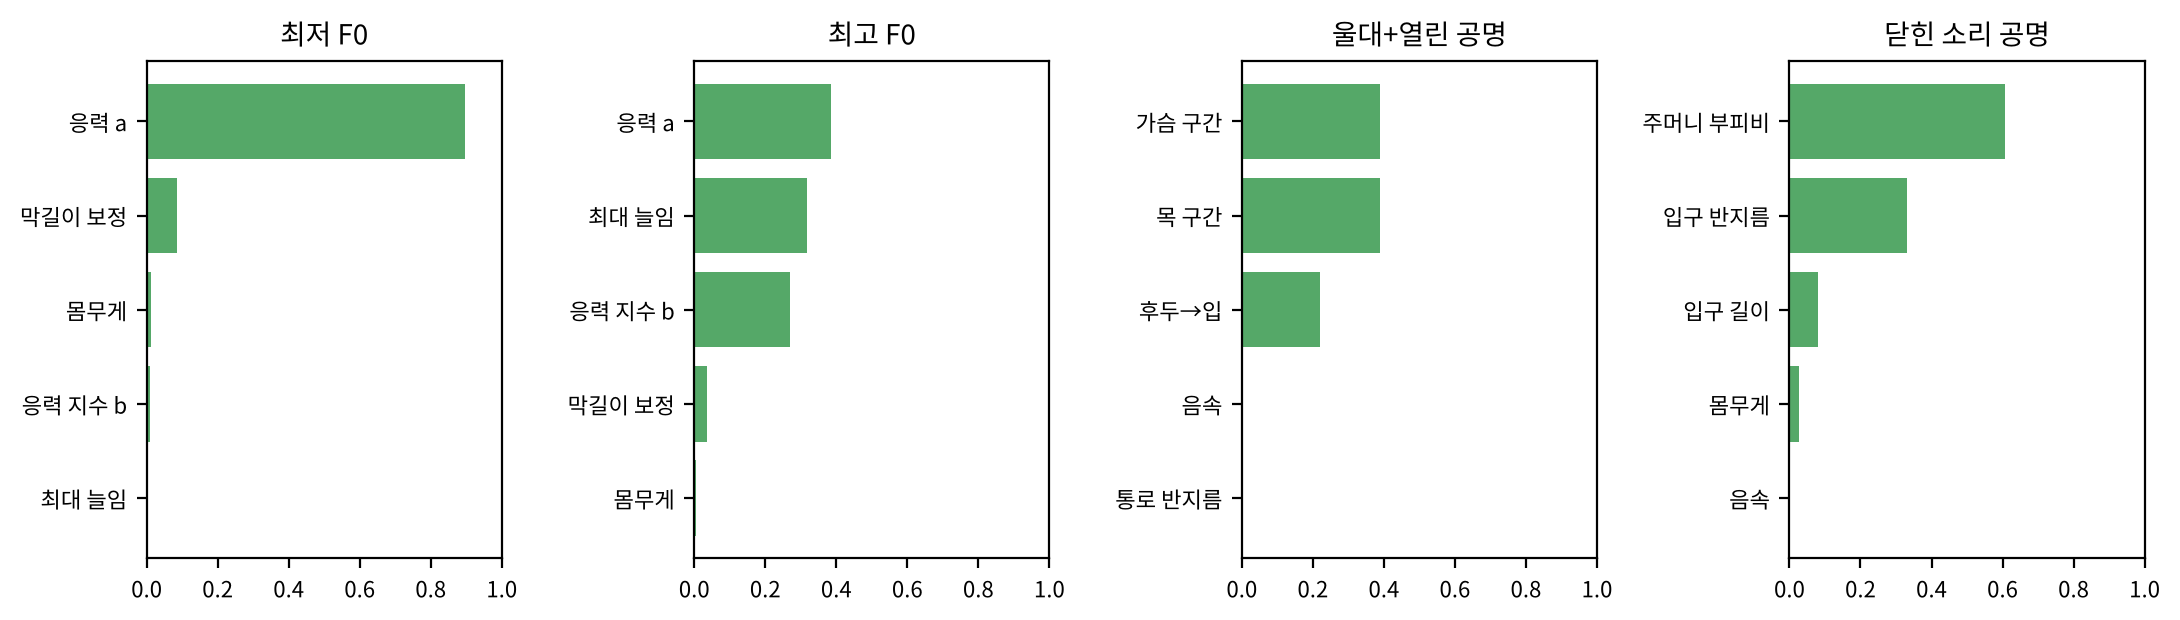

저장: result_openwind.csv, result_ranges.csv, result_sobol.csv, fig1_ranges.png, fig2_sobol.png


In [9]:
# %% [8] 그림 2 — 민감도 막대그래프
outs = ["최저 F0", "최고 F0", "울대+열린 공명", "닫힌 소리 공명"]
fig, axs = plt.subplots(1, 4, figsize=(11, 3.2), sharex=True)
for ax, o in zip(axs, outs):
    d = SS[SS.출력 == o].sort_values("ST")
    ax.barh(d.변수, d.ST.clip(lower=0), color="#55A868"); ax.set_title(o, fontsize=10)
    ax.set_xlim(0, 1); ax.tick_params(labelsize=8)
plt.tight_layout(); plt.savefig("fig2_sobol.png", dpi=200); plt.show()
print("저장: result_openwind.csv, result_ranges.csv, result_sobol.csv, fig1_ranges.png, fig2_sobol.png")